# 02 · VAD: keep only the speech

**VAD**: is there speech in this 32 ms slice? Out comes a probability.

## 2.1 · Get audio

Reuses `recordings/sample.wav`, otherwise records one.

In [4]:
from pathlib import Path

import numpy as np
import soundfile as sf
import sounddevice as sd

SAMPLE_RATE = 16_000
DURATION = 10.0
SAMPLE_PATH = Path("../recordings/sample.wav")
SAMPLE_PATH.parent.mkdir(exist_ok=True)

if SAMPLE_PATH.exists():
    audio, sr = sf.read(SAMPLE_PATH, dtype="float32")
    assert sr == SAMPLE_RATE, f"expected {SAMPLE_RATE} Hz, file is {sr} Hz"
    print(f"Loaded {SAMPLE_PATH}")
else:
    print("Recording in 1 second... remember to pause in the middle")
    sd.sleep(1000)
    print("SPEAK NOW")
    audio = sd.rec(int(DURATION * SAMPLE_RATE), samplerate=SAMPLE_RATE,
                   channels=1, dtype="float32")
    sd.wait()
    audio = audio.flatten()
    sf.write(SAMPLE_PATH, audio, SAMPLE_RATE)
    print(f"Saved to {SAMPLE_PATH}")

print(f"shape={audio.shape}  duration={len(audio)/SAMPLE_RATE:.1f}s  "
      f"RMS={np.sqrt(np.mean(audio**2)):.4f}")

Loaded ../recordings/sample.wav
shape=(160000,)  duration=10.0s  RMS=0.0248


> To re-record, delete `recordings/sample.wav` and re-run.

## 2.2 · Load the model

[Silero VAD](https://github.com/snakers4/silero-vad): about 2 MB, under 1 ms per window.

In [5]:
import time

from silero_vad import load_silero_vad, get_speech_timestamps

t0 = time.perf_counter()
model = load_silero_vad(onnx=True)
print(f"Model loaded in {time.perf_counter() - t0:.2f}s")

Model loaded in 0.12s


## 2.3 · The window size

```
512 samples / 16,000 per second = 32 ms
```

In [6]:
import torch

WINDOW = 512                       # samples. Fixed by the model at 16 kHz.
WINDOW_MS = WINDOW / SAMPLE_RATE * 1000

model.reset_states()               # the model is stateful, see the note below

probs = []
t0 = time.perf_counter()
for start in range(0, len(audio) - WINDOW + 1, WINDOW):
    window = torch.from_numpy(audio[start:start + WINDOW])
    probs.append(float(model(window, SAMPLE_RATE).item()))
elapsed = time.perf_counter() - t0

probs = np.array(probs)

print(f"{len(probs)} windows of {WINDOW_MS:.0f}ms each")
print(f"processed in {elapsed*1000:.0f}ms total, "
      f"{elapsed/len(probs)*1000:.3f}ms per window")
print(f"that is {len(audio)/SAMPLE_RATE/elapsed:.0f}x faster than real time")
print()
print(f"probability range: {probs.min():.3f} to {probs.max():.3f}")
print(f"windows above 0.5: {int((probs > 0.5).sum())} of {len(probs)}")

312 windows of 32ms each
processed in 44ms total, 0.140ms per window
that is 229x faster than real time

probability range: 0.000 to 1.000
windows above 0.5: 146 of 312


- `reset_states()`: Silero remembers previous windows, so reset per recording
- Ten seconds in a few dozen ms: VAD is essentially free

## 2.4 · Speech probability over time

Waveform on top, the model's opinion below, same time axis.

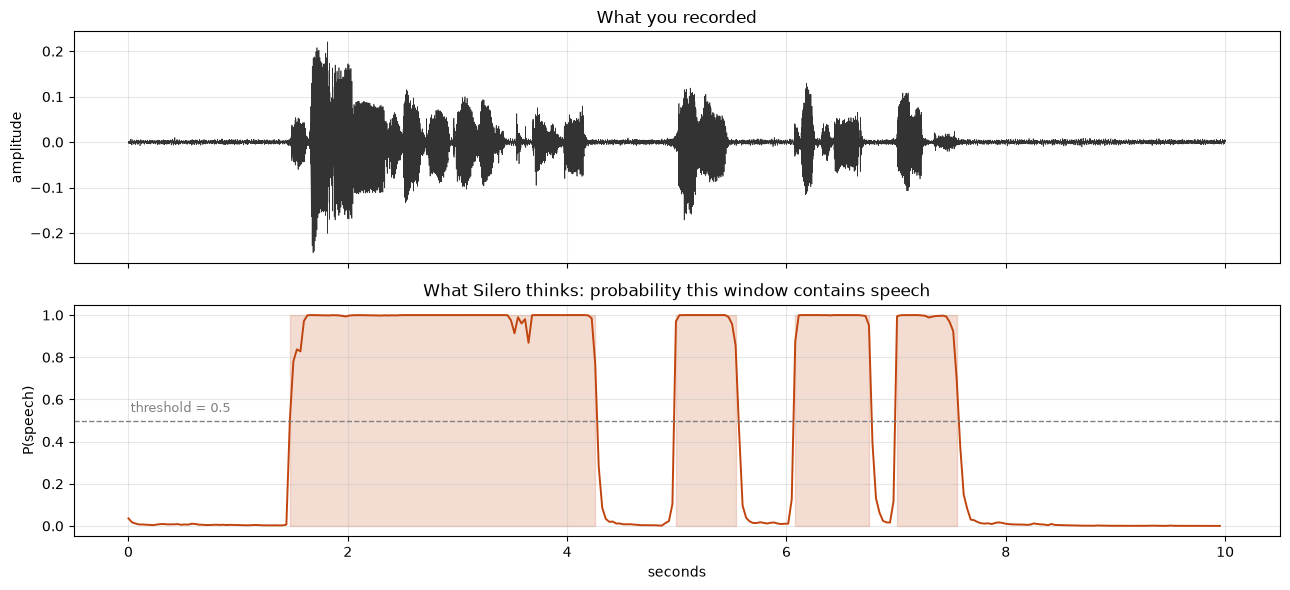

In [7]:
import matplotlib.pyplot as plt

THRESHOLD = 0.5

audio_time = np.arange(len(audio)) / SAMPLE_RATE
prob_time = np.arange(len(probs)) * WINDOW / SAMPLE_RATE

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

ax1.plot(audio_time, audio, linewidth=0.5, color="#333")
ax1.set_title("What you recorded")
ax1.set_ylabel("amplitude")
ax1.grid(alpha=0.3)

ax2.plot(prob_time, probs, linewidth=1.4, color="#c1440e")
ax2.axhline(THRESHOLD, color="gray", linestyle="--", linewidth=1)
ax2.fill_between(prob_time, 0, 1, where=probs > THRESHOLD,
                 alpha=0.18, color="#c1440e", step="mid")
ax2.text(0.02, THRESHOLD + 0.04, f"threshold = {THRESHOLD}",
         color="gray", fontsize=9)
ax2.set_title("What Silero thinks: probability this window contains speech")
ax2.set_xlabel("seconds")
ax2.set_ylabel("P(speech)")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Near 1 in speech, near 0 in pauses
- Short dips between words

## 2.5 · Why not just loudness?

White noise, louder than the voice.

In [8]:
rng = np.random.default_rng(0)
noise = (rng.standard_normal(len(audio)) * 0.05).astype("float32")

model.reset_states()
noise_probs = np.array([
    float(model(torch.from_numpy(noise[s:s + WINDOW]), SAMPLE_RATE).item())
    for s in range(0, len(noise) - WINDOW + 1, WINDOW)
])

energy_says = np.mean(np.abs(noise) > 0.02) * 100

print(f"White noise RMS        : {np.sqrt(np.mean(noise**2)):.4f}")
print(f"Your speech RMS        : {np.sqrt(np.mean(audio**2)):.4f}")
print()
print(f"Energy detector says   : {energy_says:.0f}% of samples are 'speech'")
print(f"Silero max probability : {noise_probs.max():.3f}")
print(f"Silero windows > 0.5   : {int((noise_probs > 0.5).sum())} of {len(noise_probs)}")

White noise RMS        : 0.0501
Your speech RMS        : 0.0248

Energy detector says   : 69% of samples are 'speech'
Silero max probability : 0.049
Silero windows > 0.5   : 0 of 312


- Energy detector: fooled
- Silero: not

## 2.6 · From probabilities to segments

Three settings for how long a silence must last before a segment ends.

In [9]:
configs = {
    "twitchy   (100ms silence)": dict(min_silence_duration_ms=100, speech_pad_ms=30),
    "balanced  (500ms silence)": dict(min_silence_duration_ms=500, speech_pad_ms=100),
    "patient  (1500ms silence)": dict(min_silence_duration_ms=1500, speech_pad_ms=100),
}

for name, kwargs in configs.items():
    model.reset_states()
    segments = get_speech_timestamps(
        audio, model,
        sampling_rate=SAMPLE_RATE,
        return_seconds=True,
        threshold=0.5,
        **kwargs,
    )
    speech_total = sum(s["end"] - s["start"] for s in segments)
    print(f"{name}: {len(segments)} segment(s), {speech_total:.2f}s of speech")
    for s in segments:
        print(f"      {s['start']:6.2f}s -> {s['end']:6.2f}s")
    print()

twitchy   (100ms silence): 4 segment(s), 4.90s of speech
        1.40s ->   4.30s
        5.00s ->   5.60s
        6.00s ->   6.80s
        7.00s ->   7.60s

balanced  (500ms silence): 2 segment(s), 5.80s of speech
        1.40s ->   4.40s
        4.90s ->   7.70s

patient  (1500ms silence): 1 segment(s), 6.30s of speech
        1.40s ->   7.70s



- **Twitchy** cuts you off
- **Balanced** is about right
- **Patient** waits too long